# 07 Stationscluster mit K-Means

Teil 3: Clustering

**Worum es geht**
- Lassen sich die HAST (Hausübergabestationen) anhand ihrer Kennzahlen in Betriebsprofile gruppieren?
- Methode: K-Means auf einer Kennzahl-Zeile je Station.
- Ziel ist, gesunde von auffälligen Stationen zu trennen, nicht große von kleinen.

**Daten**
- liest: `data/processed/hast_features.csv` (eine Zeile je HAST)
- schreibt: `data/processed/hast_clusters.csv` und `data/processed/hast_clusters.json` (Lauf-Kontext)
- vorher ausführen: Notebook 00

**Code**
- keine Logik in `src/`; nur pandas, numpy, matplotlib und scikit-learn

## 1 Setup und Daten laden

- Sucht die Projektwurzel: vom aktuellen Ordner nach oben, bis `data/processed` auftaucht. So läuft das Notebook aus `notebooks/` und aus dem Repo-Wurzelordner.
- Bricht mit klarer Meldung ab, wenn `hast_features.csv` fehlt.

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 40)
plt.rcParams["figure.facecolor"] = "white"

ROOT = Path.cwd().resolve()
while not (ROOT / "data" / "processed").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
FEATURES_PATH = ROOT / "data" / "processed" / "hast_features.csv"
if not FEATURES_PATH.is_file():
    raise FileNotFoundError(
        f"{FEATURES_PATH} nicht gefunden - zuerst 00_daten.ipynb laufen lassen"
    )
features = pd.read_csv(FEATURES_PATH)
print(f"{len(features)} HAST-Profile geladen")
features.drop(columns="address").head()  #ohne Adressen

93 HAST-Profile geladen


,rt_mean_winter,rt_p95,dt_mean_loaded,dt_std_loaded,rt_above_50_share_loaded,summer_flow_share,summer_flow_baseline,flow_ceiling_slope_per_month,peak_load_share,p95_load_share,flow_short_cycle_power,idle_share,energy_kwh_year,full_load_hours,Zählernummer,anschlusswert_kw,coverage,n_rows,n_hours
0,45.614801,58.5,29.575008,8.451971,0.319709,0.605441,20.0,-6.152177,1.7325,0.983,0.139289,0.354887,4.143699e+04,1195.872608,53198226,20.0,0.686198,22193,32342
1,41.199395,49.1,31.884356,5.927171,0.033037,0.085217,0.0,-4.766754,NaN,NaN,0.128650,0.447939,1.436235e+04,930.143977,58177363,NaN,0.609600,13513,22167
2,53.493089,59.5,22.788473,5.697562,0.651170,0.314597,0.0,-11.896678,NaN,NaN,0.133458,0.298658,3.066944e+04,2541.806879,58177384,NaN,0.511487,9017,17629
3,58.711979,74.2,NaN,NaN,0.999921,0.912609,7820.0,228.286667,NaN,NaN,0.101974,0.060983,1.911474e+06,5805.045621,58202380,NaN,0.609555,13512,22167
4,43.459029,63.5,23.628571,9.528109,0.347671,0.102609,0.0,-0.936316,NaN,NaN,0.243884,0.588475,5.866872e+03,486.231757,61620222,NaN,0.609798,13518,22168


- 93 HAST-Profile mit 20 Spalten: 14 Kennzahlen, dazu Zählernummer, Adresse, Anschlusswert und Angaben zur Abdeckung (`coverage`, `n_rows`, `n_hours`).
- Jede HAST ist eine Zeile. Das ist das Format, das K-Means braucht.

## 2 Merkmale auswählen und vorverarbeiten

- 10 von 14 Kennzahlen. Weggelassen: `rt_p95` und `rt_above_50_share_loaded` (doppeln `rt_mean_winter`), `summer_flow_share` (Zwilling von `summer_flow_baseline`) und `energy_kwh_year` (Größenmaß, würde groß gegen klein trennen statt gesund gegen auffällig).
- Fehlende Werte werden mit dem Median gefüllt. Median statt Mittelwert, weil er weniger auf Ausreißer reagiert. Nebenwirkung: aufgefüllte Stationen rücken zur Mitte.
- Extremwerte werden am 1. und 99. Perzentil gekappt (Clipping), danach wird standardisiert (z-Transformation: Mittelwert 0, Streuung 1).
- Unendliche Werte aus Divisionen werden vorher zu fehlenden Werten, sonst wäre die Standardisierung der ganzen Spalte kaputt.

In [2]:
CLUSTER_FEATURES = [
    "rt_mean_winter", "dt_mean_loaded", "dt_std_loaded",
    "summer_flow_baseline", "flow_ceiling_slope_per_month",
    "peak_load_share", "p95_load_share", "flow_short_cycle_power",
    "idle_share", "full_load_hours",
]

X_raw = features[CLUSTER_FEATURES].replace([np.inf, -np.inf], np.nan)
missing_share = (X_raw.isna().mean() * 100).sort_values(ascending=False)
print("Anteil fehlender Werte je Cluster-Feature:")
display(missing_share.round(1).to_frame("% fehlend"))

imputer = SimpleImputer(strategy="median")
X_imputed = pd.DataFrame(imputer.fit_transform(X_raw), columns=CLUSTER_FEATURES)

bounds = X_imputed.quantile([0.01, 0.99])
X_clipped = X_imputed.clip(lower=bounds.loc[0.01], upper=bounds.loc[0.99], axis=1)

scaler = StandardScaler()
X = scaler.fit_transform(X_clipped)
print(f"Cluster-Matrix: {X.shape[0]} HAST × {X.shape[1]} Features")
print(f"Zeilen mit mindestens einem fehlenden Wert: {int(X_raw.isna().any(axis=1).sum())} von {len(X_raw)}")
print(f"Clipping summer_flow_baseline: Maximum {X_imputed['summer_flow_baseline'].max():.0f} -> {X_clipped['summer_flow_baseline'].max():.0f} l/h, "
      f"Steigung: Minimum {X_imputed['flow_ceiling_slope_per_month'].min():.0f} -> {X_clipped['flow_ceiling_slope_per_month'].min():.0f}")
print(f"Streuung vor dem Standardisieren: summer_flow_baseline {X_clipped['summer_flow_baseline'].std():.0f} l/h, idle_share {X_clipped['idle_share'].std():.2f}")
print(f"Korrelation rt_mean_winter / dt_mean_loaded: r = {X_clipped['rt_mean_winter'].corr(X_clipped['dt_mean_loaded']):.2f}")

Anteil fehlender Werte je Cluster-Feature:


,% fehlend
peak_load_share,6.5
p95_load_share,6.5
dt_mean_loaded,1.1
dt_std_loaded,1.1
rt_mean_winter,0.0
summer_flow_baseline,0.0
flow_ceiling_slope_per_month,0.0
flow_short_cycle_power,0.0
idle_share,0.0
full_load_hours,0.0


Cluster-Matrix: 93 HAST × 10 Features
Zeilen mit mindestens einem fehlenden Wert: 6 von 93
Clipping summer_flow_baseline: Maximum 7820 -> 2714 l/h, Steigung: Minimum -1024 -> -168
Streuung vor dem Standardisieren: summer_flow_baseline 437 l/h, idle_share 0.19
Korrelation rt_mean_winter / dt_mean_loaded: r = -0.87


- Fehlende Werte vor dem Auffüllen: `peak_load_share` und `p95_load_share` je 6,5 % (6 HAST ohne Anschlusswert), `dt_mean_loaded` und `dt_std_loaded` je 1,1 % (nie über 0,5 kW gelaufen). Betroffen sind 6 von 93 Zeilen.
- Clipping betrifft nur 1 bis 2 Werte je Merkmal, kappt aber stark (`summer_flow_baseline` 7 820 auf 2 714, Steigung −1 024 auf −168). Nötig, weil K-Means quadrierte Abstände nutzt; ein Ausreißer zieht sonst ein Zentrum zu sich.
- Standardisieren ist Pflicht: Die Streuung liegt beim Durchfluss bei etwa 437 l/h, bei `idle_share` (Anteil der Leerlaufstunden) bei 0,19. Ohne z-Transformation bestimmen Durchfluss und Volllaststunden fast allein den Abstand.
- Zu diskutieren: `rt_mean_winter` und `dt_mean_loaded` korrelieren mit r = −0,87. Dieses Thema zählt im Abstand doppelt.

## 3 Anzahl der Cluster wählen

- K-Means bestimmt k nicht selbst. Getestet werden k = 2 bis 8; mehr ergibt bei 93 HAST nur noch Splitter.
- Inertia = Summe der quadrierten Abstände zum eigenen Zentrum. Sie sinkt immer mit k; gesucht ist ein Knick (Elbow).
- Silhouette = je Station (b − a) / max(a, b), mit a = Abstand zum eigenen Cluster und b = Abstand zum nächsten. Werte von −1 bis 1: über 0,5 stark, 0,25 bis 0,5 schwach, unter 0,25 keine echte Struktur.
- Je k 20 Starts (`n_init=20`), der beste zählt; Seed 42 für Reproduzierbarkeit.

,k,inertia,silhouette
0,2,748.714,0.237
1,3,658.381,0.219
2,4,573.408,0.157
3,5,515.678,0.165
4,6,454.342,0.185
5,7,411.416,0.170
6,8,367.451,0.194


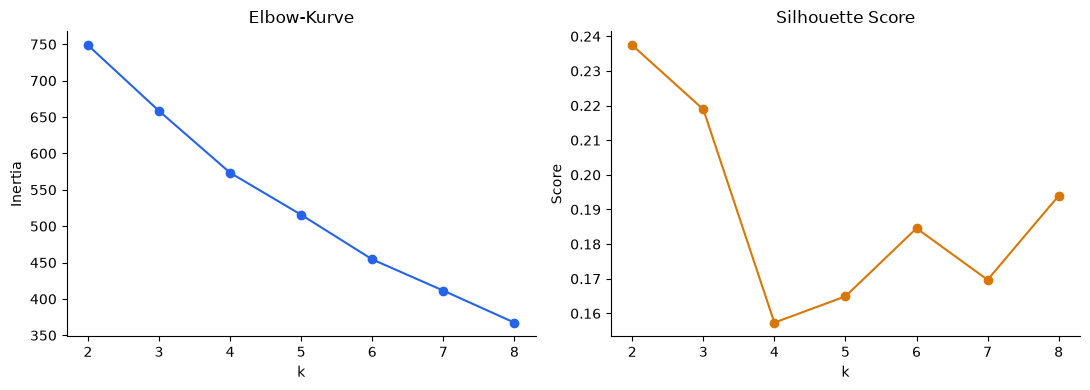

In [3]:
k_values = range(2, 9)
rows = []
for k in k_values:
    model = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
    rows.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X, model.labels_),
    })
k_metrics = pd.DataFrame(rows)
display(k_metrics.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(k_metrics["k"], k_metrics["inertia"], marker="o", color="#2563EB")
axes[0].set(title="Elbow-Kurve", xlabel="k", ylabel="Inertia")
axes[1].plot(k_metrics["k"], k_metrics["silhouette"], marker="o", color="#D97706")
axes[1].set(title="Silhouette Score", xlabel="k", ylabel="Score")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

93 HAST, ohne BHKW, Kessel und Temperaturfühler:
- Kein echter Knick: Die Inertia fällt um 9 bis 13 % je Schritt.
- Beste Silhouette bei k = 2 mit 0,237, knapp vor k = 3 mit 0,219. Alle Werte liegen unter 0,25, also keine echte Struktur.
- Mit BHKW und Kesseln lag k = 2 bei 0,599, weil drei Ausreißer abgetrennt wurden (97/3). Der hohe Wert war ein Effekt des Stationstyps, keine Struktur in der Flotte.

## 4 Finales Modell

- k wird automatisch über die beste Silhouette gewählt; bei Bedarf hier überschreiben.
- 50 Starts statt 20, weil dieses eine Modell alles Weitere trägt.
- Die Labels werden über die Zeilenreihenfolge zugeordnet. Das geht nur, weil in Abschnitt 2 keine Zeile gelöscht wurde; ein `dropna()` dort würde Labels falschen Stationen zuweisen.
- Clusternummern sind Etiketten, keine Rangfolge.

In [4]:
K = int(k_metrics.loc[k_metrics["silhouette"].idxmax(), "k"])
print(f"Gewähltes k (bester Silhouette Score): {K}")

kmeans = KMeans(n_clusters=K, n_init=50, random_state=42).fit(X)
features["cluster"] = kmeans.labels_
#zum Vergleich k = 3: Größen und der kleinste Cluster
k3 = KMeans(n_clusters=3, n_init=50, random_state=42).fit(X).labels_
g3 = pd.Series(k3).value_counts()
print("k = 3:", "/".join(str(n) for n in g3.sort_index()), "| kleinster Cluster:",
      sorted(features.loc[k3 == g3.idxmin(), "Zählernummer"].astype(int)))
features["cluster"].value_counts().sort_index()

Gewähltes k (bester Silhouette Score): 2
k = 3: 31/59/3 | kleinster Cluster: [58202380, 66761022, 81050517]


cluster
0    31
1    62
Name: count, dtype: int64

Ergebnis: k = 2, Größen 31 und 62.
- Cluster 0 (31 HAST): Rücklauf 55,4 °C, Spreizung (Vorlauf minus Rücklauf) 15,9 K, Sommer-Durchfluss 48 l/h, `idle_share` 0,25. Stationen, die auch im Sommer umwälzen und dabei wenig auskühlen.
- Cluster 1 (62 HAST): Rücklauf 42,2 °C, Spreizung 28,3 K, kein Sommer-Durchfluss, `idle_share` 0,43. Normalbetrieb.
- Getrennt wird nach Rücklauf, Spreizung und Sommer-Durchfluss. Die Volllaststunden trennen kaum (1 106 gegen 944 h).
- k = 2 und k = 3 liegen dicht beieinander (0,237 gegen 0,219); die automatische Wahl ist keine klare Entscheidung. Bei k = 3 (31/59/3) spaltet sich ein Kleinst-Cluster ab: 58202380, 66761022 und 81050517.

## 5 Cluster in zwei Dimensionen zeigen (PCA)

- PCA (Hauptkomponentenanalyse) dreht die Punktwolke aus 10 Merkmalen so, dass die Richtung größter Streuung zur x-Achse wird (PC1) und die zweitgrößte zur y-Achse (PC2).
- Beide Achsen mischen alle 10 Merkmale. Die Ladungstabelle zeigt, wie stark jedes Merkmal eingeht, sortiert nach dem Betrag der PC1-Ladung.
- PCA läuft auf den standardisierten Daten. Ohne z-Transformation wäre PC1 einfach die Richtung von `summer_flow_baseline`.

Erklärte Varianz: PC1 29.8%, PC2 18.7% — zusammen 48.5%


,PC1,PC2
rt_mean_winter,0.48,0.33
idle_share,-0.42,0.23
flow_short_cycle_power,-0.39,-0.06
dt_mean_loaded,-0.37,-0.37
summer_flow_baseline,0.37,0.03
full_load_hours,0.33,-0.42
dt_std_loaded,-0.17,0.23
peak_load_share,-0.12,0.57
flow_ceiling_slope_per_month,-0.10,-0.25
p95_load_share,-0.06,0.28


Mittel auf PC1 je Cluster: {0: 1.9, 1: -0.9}


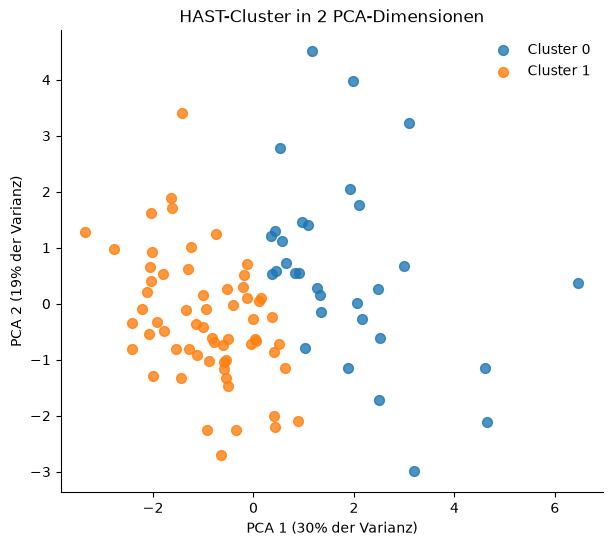

In [5]:
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X)
ev = pca.explained_variance_ratio_
print(f"Erklärte Varianz: PC1 {ev[0]:.1%}, PC2 {ev[1]:.1%} — zusammen {ev.sum():.1%}")

loadings = pd.DataFrame(pca.components_.T, index=CLUSTER_FEATURES, columns=["PC1", "PC2"])
display(loadings.reindex(loadings["PC1"].abs().sort_values(ascending=False).index).round(2))
print("Mittel auf PC1 je Cluster:", pd.Series(coords[:, 0]).groupby(features["cluster"].to_numpy()).mean().round(1).to_dict())

fig, ax = plt.subplots(figsize=(7, 6))
palette = plt.cm.tab10.colors
for cluster in sorted(features["cluster"].unique()):
    mask = features["cluster"] == cluster
    ax.scatter(coords[mask, 0], coords[mask, 1], s=50, alpha=0.8,
               color=palette[cluster % len(palette)], label=f"Cluster {cluster}")
ax.set(title="HAST-Cluster in 2 PCA-Dimensionen",
       xlabel=f"PCA 1 ({ev[0]:.0%} der Varianz)",
       ylabel=f"PCA 2 ({ev[1]:.0%} der Varianz)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

- PC1 erklärt 29,8 %, PC2 18,7 %, zusammen 48,5 %. Rund die Hälfte der Streuung fehlt im Bild; es ist eine Plausibilitätsprüfung, kein Beweis.
- Die Achsen haben keine Einheit, das Vorzeichen ist beliebig. Nur Abstände und Nachbarschaften zählen.
- PC1 ist die Rücklauf-Durchfluss-Achse: hoher `rt_mean_winter` (+0,48) und Sommer-Durchfluss (+0,37) gegen `idle_share` (−0,42), `flow_short_cycle_power` (−0,39) und Spreizung `dt_mean_loaded` (−0,37). Nach dieser Achse trennt auch K-Means (Cluster 0 im Mittel bei PC1 ≈ +1,9, Cluster 1 bei ≈ −0,9).
- PC2 ist gemischt: `peak_load_share` (+0,57) gegen Volllaststunden (−0,42) und Spreizung (−0,37), dazu Rücklauf (+0,33).

## 6 Clusterprofile

- Median je Cluster und Merkmal, in echten Einheiten (°C, K, l/h, h) statt in Standardabweichungen. Hier bekommen die Cluster ihre Bedeutung.
- Median statt Mittelwert, passend zum Clipping: Ein Extremwert soll das Profil nicht verziehen.
- Gerechnet auf den Originalwerten mit ihren echten Lücken. Die Fallzahl schwankt deshalb je Merkmal.
- Die letzte Zeile ist der Median der ganzen Flotte.

In [6]:
profile = features.groupby("cluster")[CLUSTER_FEATURES].median()
profile.loc["Flotte"] = features[CLUSTER_FEATURES].median()
sizes = features["cluster"].value_counts().rename("n_hast")
sizes["Flotte"] = len(features)
display(profile.round(3).join(sizes))
#Stationen mit den meisten auffälligen Monaten in Notebook 03
print(features.set_index("Zählernummer").loc[[72167782, 72167783, 68956351, 80912182], "cluster"].to_dict())

,rt_mean_winter,dt_mean_loaded,dt_std_loaded,summer_flow_baseline,flow_ceiling_slope_per_month,peak_load_share,p95_load_share,flow_short_cycle_power,idle_share,full_load_hours,n_hast
cluster,,,,,,,,,,,
0,55.368,15.922,7.669,48.0,-3.194,1.610,0.633,0.104,0.246,1106.093,31
1,42.227,28.349,8.073,0.0,-0.952,1.673,0.651,0.206,0.427,943.750,62
Flotte,44.485,26.240,7.951,0.0,-1.400,1.668,0.650,0.182,0.382,982.090,93


{72167782: 0, 72167783: 1, 68956351: 0, 80912182: 0}


Vergleich mit dem Flottenmedian:
- Cluster 0 (31 HAST) ist auffällig: Rücklauf 55,4 °C (Flotte 44,5), Spreizung 15,9 K (Flotte 26,2), Sommer-Durchfluss 48 l/h (Flotte 0), `idle_share` 0,25. Das Bild einer Station, die durchgehend umwälzt, ohne viel Wärme abzugeben.
- Das passt zu Zirkulationsverlusten, hydraulischem Kurzschluss oder einem nicht schließenden Ventil. Netzseitig teuer, weil hoher Rücklauf die Vorlauftemperatur der ganzen Leitung hochzieht.
- Cluster 1 (62 HAST) ist Normalbetrieb: Spreizung 28,3 K, kein Sommer-Durchfluss, `idle_share` 0,43. Die Station öffnet bei Bedarf, sonst ist sie zu.
- Der höhere `flow_short_cycle_power` in Cluster 1 (0,21 gegen 0,10) ist kein Widerspruch: Wer taktet, hat kurze Zyklen; wer durchläuft, hat keine.

## 7 Ergebnis speichern

- Schreibt Zählernummer, Adresse, Cluster, `coverage` und die 10 Merkmale nach `data/processed/hast_clusters.csv`.
- `coverage` = Anteil echter Messstunden je Station (46 % bis 100 %). Damit lässt sich später prüfen, ob ein auffälliger Wert auf genug Daten beruht.
- Lauf-Kontext als JSON daneben: k, Silhouette, Seed, Vorverarbeitung, Clustergrößen und Merkmalsliste. Wichtig, weil k automatisch gewählt wird und sich mit neuen Daten ändern kann.

In [7]:
out_path = ROOT / "data" / "processed" / "hast_clusters.csv"
export_cols = ["Zählernummer", "address", "cluster", "coverage"] + CLUSTER_FEATURES
features[export_cols].to_csv(out_path, index=False)

meta_path = out_path.with_suffix(".json")
meta = {
    "erzeugt": pd.Timestamp.now().isoformat(timespec="seconds"),
    "quelle": str(FEATURES_PATH.relative_to(ROOT)),
    "n_hast": int(len(features)),
    "k": int(K),
    "silhouette": round(float(k_metrics.loc[k_metrics["k"] == K, "silhouette"].iloc[0]), 4),
    "random_state": 42,
    "vorverarbeitung": "Median-Imputation -> Clipping 1./99. Perzentil -> StandardScaler",
    "cluster_features": CLUSTER_FEATURES,
    "clustergroessen": {int(c): int(n) for c, n in features["cluster"].value_counts().sort_index().items()},
    "coverage_min": round(float(features["coverage"].min()), 3),
}
meta_path.write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")

print(f"Cluster-Zuordnung -> {out_path}")
print(f"Lauf-Kontext      -> {meta_path}")

Cluster-Zuordnung -> /Users/ivelinayaneva/projektseminar/data/processed/hast_clusters.csv
Lauf-Kontext      -> /Users/ivelinayaneva/projektseminar/data/processed/hast_clusters.json


- Der Name der JSON-Datei wird aus dem CSV-Pfad abgeleitet; beide Dateien bleiben so gepaart.
- Die CSV enthält Zählernummern und Adressen. `data/processed/` ist gitignored und bleibt es (Datenschutz-Abschnitt in [`docs/datengrundlage/quellen.md`](../../docs/datengrundlage/quellen.md)).

## Zusammenfassung & Bewertung

**Ergebnis**
- Lauf mit 93 HAST. Acht Zähler sind laut ÜZ keine HAST (BHKW, HHS-Kessel I bis IV, Ölspitzenkessel, zwei Temperaturfühler) und werden seit Notebook 00 ausgeschlossen.
- k = 2, Aufteilung 31/62, Silhouette 0,237.

| Kennzahl | Cluster 0 (31) | Cluster 1 (62) | Flotte |
|---|---|---|---|
| `rt_mean_winter` | 55,4 °C | 42,2 °C | 44,5 °C |
| `dt_mean_loaded` | 15,9 K | 28,3 K | 26,2 K |
| `summer_flow_baseline` | 48 l/h | 0 l/h | 0 l/h |
| `idle_share` | 0,25 | 0,43 | 0,38 |
| `full_load_hours` | 1 106 | 944 | 982 |

- Cluster 0 zeigt hohen Rücklauf, geringe Spreizung und Sommer-Durchfluss. Das ist das Muster der physikalischen Defektregel aus Notebook 03 ([`03_labels`](../2_begehungen/03_labels.ipynb)). Drei der vier Stationen mit den meisten auffälligen Monaten dort (68956351, 72167782, 80912182) liegen in Cluster 0.

**Belastbar**
- Die Trennung ist fachlich lesbar: Sie folgt Rücklauf, Spreizung und Sommer-Durchfluss, nicht der Größe.
- Der frühere hohe Wert (k = 2, Silhouette 0,599, Aufteilung 97/3) war ein Effekt des Stationstyps. Das Verfahren hat Erzeuger von Verbrauchern getrennt, darunter das BHKW 86792512.
- Notebook 09 bestätigt die Kernaussage: Alle drei Gewichtungswege legen die Ausreißer 58202380 und 66761022 in den kleinsten Cluster, der Rest bleibt ein Kontinuum. Redundanzabbau hebt die Silhouette bei k = 3 nur von 0,261 auf 0,272; PCA auf 90 % Varianz liefert fast dieselbe Partition wie der ungewichtete Weg (ARI 0,96). Empfehlung für die Abgabe: redundanzbereinigte Merkmalsauswahl, nicht PCA.
- Seit dem letzten Lauf behoben:
  - `full_load_hours` ist jetzt ein Jahreswert (Normierung auf 8 760 h/Jahr in `src/features.py` und Notebook 00, Test in `tests/test_features.py`). Maximum in der Flotte 5 805 statt 14 689 Volllaststunden.
  - Adressen werden über `_normalize_address()` aus [`src/load_data.py`](../../src/load_data.py) abgeglichen (58 Treffer).
  - Der Lauf-Kontext wird als `hast_clusters.json` mitgespeichert.

**Schwach**
- Silhouette unter 0,25: Die Flotte ist eher ein Kontinuum als eine Menge klarer Typen.
- k = 2 und k = 3 liegen dicht beieinander (0,237 gegen 0,219). Die Wahl von k ist damit wieder offen.
- Getrennt je Leistungsklasse zu clustern verschlechtert das Ergebnis deutlich (Notebook 09), weil die Klassen mit 52 und 32 Stationen zu klein sind. Die Klasse gehört als Kontextgröße dazu.
- Abgleich mit den Begehungen (58 Stationen, Join über `_normalize_address()`): Er galt der alten 97/3-Aufteilung, damals lagen alle begangenen Stationen in Cluster 0. Basisrate 76 %; das Problem ist das Label, nicht die Methode.

**Offen**
- Abgleich mit den Begehungen für die 31/62-Aufteilung neu rechnen.
- `coverage` nutzen: Die Abdeckung reicht von 46 % bis 100 %, derzeit zählen alle Stationen gleich.
- Stationstyp von 58202380 und 66761022 klären: erst in die Rohzeitreihen schauen (echter Betrieb oder defekter Zähler?), dann ÜZ fragen. Beide fehlen in den Begehungsakten und haben keinen Topologie-Treffer; Auflösung über `Zuordnung.xlsx` steht aus.